In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
templates_info = {
    'cédula-2-reais_anverso.jpg': 2,
    'cédula-5-reais_anverso.jpg': 5,
    'cédula-10-reais_anverso.jpg': 10,
    'cédula-20-reais_anverso.jpg': 20,
    'cédula-50-reais_anverso.jpg': 50,
    'cédula-100-reais_anverso.jpg': 100,
    'cédula-200-reais_anverso.jpg': 200
}
hsv_ranges_info = {
    2: {
        'lower': np.array([100, 6, 237]),
        'upper': np.array([116, 118, 255])
    },
    5: {
        'lower': np.array([124, 6, 231]),
        'upper': np.array([165, 68, 255])
    },
    10: {
        'lower': np.array([0, 0, 250]),
        'upper': np.array([10, 48, 255])
    },
    20: {
        'lower': np.array([17, 39, 248]),
        'upper': np.array([27, 255, 255])
    },
    50: {
        'lower': np.array([13, 20, 225]),
        'upper': np.array([22, 52, 252])
    },
    100: {
        'lower': np.array([25, 10, 218]),
        'upper': np.array([101, 38, 252])
    },
    200: {
        'lower': np.array([0, 0, 185]),
        'upper': np.array([179, 8, 255])
    }
}

# Instancia o detector global para o frame
orb_detector = cv2.ORB_create(nfeatures=20000, fastThreshold=30)
orb = cv2.ORB_create(
    nfeatures=500,
    edgeThreshold=5,
    fastThreshold=20
)

# Recarrega o frame original
frame_final = cv2.imread('montante.jpg')
frame_final_gray = cv2.cvtColor(frame_final, cv2.COLOR_BGR2GRAY)
frame_final_hsv = cv2.cvtColor(frame_final, cv2.COLOR_BGR2HSV)

total_acumulado = 0
cedulas_detectadas = []

# Parâmetros de matching
MIN_MATCH_COUNT = 8  # Mínimo de bons matches para considerar uma detecção
ratio_threshold = 0.75  # Limiar para o teste de ratio de Lowe

templates_data = {}

In [3]:
for filename, valor in templates_info.items():
    # Carrega a imagem em escala de cinza
    img = cv2.imread(filename, 0)
    if img is None:
        print(f"AVISO: Template '{filename}' não encontrado. Pulando.")
        continue

    # Calcula o offset proporcionalmente (por exemplo, pegando os 22% finais da imagem à direita)
    # 350 / 447 ≈ 0.783
    h, w = img.shape
    x_offset = int(w * 0.78)
    img_cortada = img[:80, x_offset:]

    # Detecta keypoints e descritores apenas na região cortada à direita
    kp_cortado, des = orb.detectAndCompute(img_cortada, None)

    # Ajusta as coordenadas X dos keypoints somando o offset proporcional
    kp = []
    if kp_cortado is not None:
        for k in kp_cortado:
            novo_kp = cv2.KeyPoint(
                x=k.pt[0] + x_offset,
                y=k.pt[1],
                size=k.size,
                angle=k.angle,
                response=k.response,
                octave=k.octave,
                class_id=k.class_id
            )
            kp.append(novo_kp)

    if des is not None and len(kp) > 0:
        # Busca os limites HSV correspondentes ao valor no dicionário hsv_ranges_info
        hsv_bounds = hsv_ranges_info.get(valor, {'lower': None, 'upper': None})

        templates_data[filename] = {
            'kp': kp,
            'des': des,

            'valor': valor,
            'lower': hsv_bounds['lower'],
            'upper': hsv_bounds['upper']
        }
        hsv_status = "com limites HSV" if hsv_bounds['lower'] is not None else "sem limites HSV"
        print(f"Template '{filename}' (R$ {valor}) processado com {len(kp)} keypoints ({hsv_status}).")
    else:
        print(f"AVISO: Nenhum descritor encontrado para '{filename}' na região cortada.")

if not templates_data:
    print("ERRO: Nenhum template válido foi carregado. Encerrando.")
    exit()

Template 'cédula-2-reais_anverso.jpg' (R$ 2) processado com 295 keypoints (com limites HSV).
Template 'cédula-5-reais_anverso.jpg' (R$ 5) processado com 169 keypoints (com limites HSV).
Template 'cédula-10-reais_anverso.jpg' (R$ 10) processado com 267 keypoints (com limites HSV).
Template 'cédula-20-reais_anverso.jpg' (R$ 20) processado com 370 keypoints (com limites HSV).
Template 'cédula-50-reais_anverso.jpg' (R$ 50) processado com 369 keypoints (com limites HSV).
Template 'cédula-100-reais_anverso.jpg' (R$ 100) processado com 370 keypoints (com limites HSV).
Template 'cédula-200-reais_anverso.jpg' (R$ 200) processado com 342 keypoints (com limites HSV).


[DETECTADA] Cédula de R$ 2 confirmada geometricamente (Bons Matches Reais: 22)
[DETECTADA] Cédula de R$ 5 confirmada geometricamente (Bons Matches Reais: 15)
[DETECTADA] Cédula de R$ 10 confirmada geometricamente (Bons Matches Reais: 39)
[DETECTADA] Cédula de R$ 20 confirmada geometricamente (Bons Matches Reais: 27)
[DETECTADA] Cédula de R$ 50 confirmada geometricamente (Bons Matches Reais: 24)
[DETECTADA] Cédula de R$ 100 confirmada geometricamente (Bons Matches Reais: 60)
[DETECTADA] Cédula de R$ 200 confirmada geometricamente (Bons Matches Reais: 100)


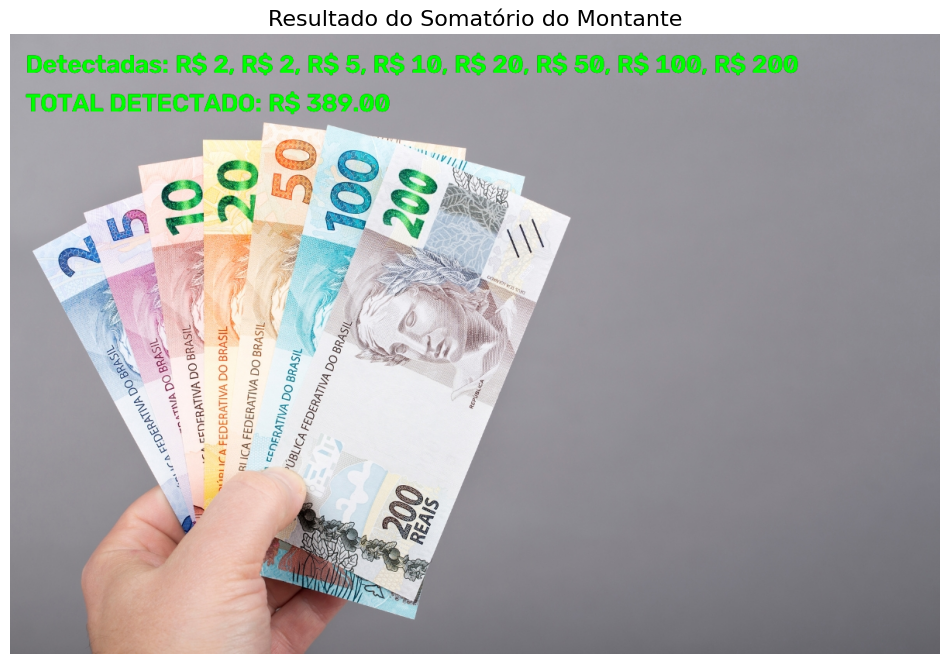

In [5]:
kp_frame_f, des_frame_f = orb_detector.detectAndCompute(frame_final_gray, None)

# Percorre cada denominação possível
for filename, valor in templates_data.items():
    if filename not in templates_data:
        continue

    # Cria máscara para isolar a cédula no frame
    mask_val = cv2.inRange(frame_final_hsv, valor['lower'], valor['upper'])
    kernel_m = np.ones((3,3), np.uint8)
    mask_val = cv2.morphologyEx(mask_val, cv2.MORPH_OPEN, kernel_m)
    mask_val = cv2.morphologyEx(mask_val, cv2.MORPH_CLOSE, kernel_m)

    contornos, _ = cv2.findContours(mask_val, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contornos) == 0:
        continue

    # Encontra o bounding box dos maiores contornos correspondentes à cor
    contornos_ordenados = sorted(contornos, key=cv2.contourArea, reverse=True)
    maiores_contornos = contornos_ordenados[:2]
    pontos_selecionados = np.vstack(maiores_contornos)
    x, y, w, h = cv2.boundingRect(pontos_selecionados)

    # Filtra os keypoints do frame contidos dentro desse bounding box
    kp_filtrados = []
    des_filtrados_lista = []
    for i, kp_f in enumerate(kp_frame_f):
        xf, yf = int(kp_f.pt[0]), int(kp_f.pt[1])
        if x <= xf < x+w and y <= yf < y+h:
            kp_filtrados.append(kp_f)
            des_filtrados_lista.append(des_frame_f[i])

    if len(des_filtrados_lista) < 8:
        continue

    des_filtrados_arr = np.array(des_filtrados_lista, dtype=np.uint8)
    bf_val = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
    matches_val = bf_val.knnMatch(des_filtrados_arr, valor['des'], k=2)

    good_matches = []
    for m_pair in matches_val:
        if len(m_pair) == 2:
            m, n = m_pair
            if m.distance < ratio_threshold * n.distance:
                good_matches.append(m)

    # Se o RANSAC confirmar o alinhamento, somamos o valor da cédula
    if len(good_matches) >= 4:
        total_acumulado += valor['valor']
        cedulas_detectadas.append(valor['valor'])
        print(f"[DETECTADA] Cédula de R$ {valor['valor']} confirmada geometricamente (Bons Matches Reais: {len(good_matches)})")

# Adiciona as informações textuais no frame de exibição final
frame_exibicao = frame_final.copy()

# Desenha a lista de notas detectadas no topo
texto_detecoes = f"Detectadas: " + ", ".join([f"R$ {c}" for c in sorted(cedulas_detectadas)])
texto_total = f"TOTAL DETECTADO: R$ {total_acumulado:.2f}"

# Escreve o texto com um contorno/fundo de contraste no topo esquerdo
pos_y = 50
for t in [texto_detecoes, texto_total]:
    cv2.putText(frame_exibicao, t, (20, pos_y), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(frame_exibicao, t, (20, pos_y), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 255, 0), 2, cv2.LINE_AA)
    pos_y += 50

# Exibe o resultado final de forma clara
plt.figure(figsize=(12, 10))
plt.title("Resultado do Somatório do Montante", fontsize=16)
plt.imshow(cv2.cvtColor(frame_exibicao, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

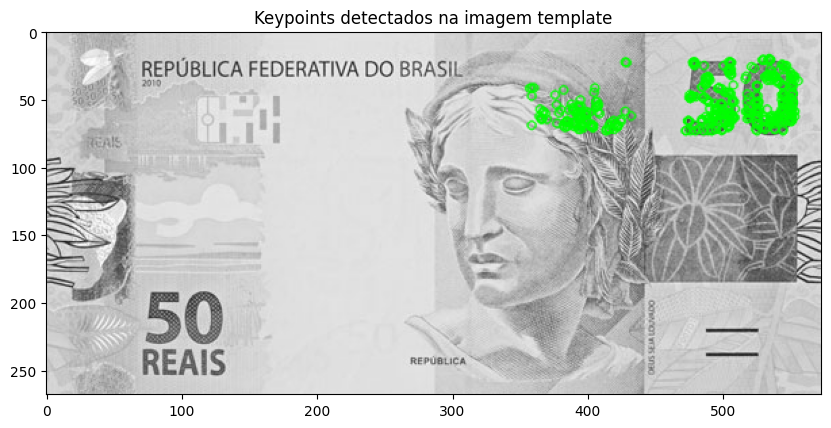

In [6]:
orb = cv2.ORB_create(
    nfeatures=500,
    edgeThreshold=5,
    fastThreshold=20
)
img_2 = cv2.imread('cédula-50-reais_anverso.jpg')
img_2_gray = cv2.cvtColor(img_2, cv2.COLOR_BGR2GRAY)

# 3. Define o corte (neste caso, offset de 350 no eixo X)
# [:, 350:] significa que o Y começa em 0 e o X começa em 350
x_offset = 350
img_cortada = img_2_gray[:80, x_offset:]

# 4. Detecta os keypoints apenas na região cortada
kp_cortado, des_2 = orb.detectAndCompute(img_cortada, None)

# 5. Ajusta as coordenadas dos keypoints somando o offset no eixo X (pt[0])
kp_ajustado = []
for kp in kp_cortado:
    # Cria um novo KeyPoint com a coordenada X ajustada (kp.pt[0] + x_offset)
    novo_kp = cv2.KeyPoint(
        x=kp.pt[0] + x_offset,
        y=kp.pt[1],
        size=kp.size,
        angle=kp.angle,
        response=kp.response,
        octave=kp.octave,
        class_id=kp.class_id
    )
    kp_ajustado.append(novo_kp)

# 6. Desenha os keypoints ajustados na imagem original inteira
img_2_gray = cv2.drawKeypoints(
    img_2_gray,
    kp_ajustado,
    outImage=None,
    color=(0, 255, 0),
    flags=cv2.DrawMatchesFlags_DEFAULT
)

plt.figure(figsize=(10, 10))
plt.title("Keypoints detectados na imagem template")
plt.imshow(cv2.cvtColor(img_2_gray, cv2.COLOR_BGR2RGB))
plt.show()

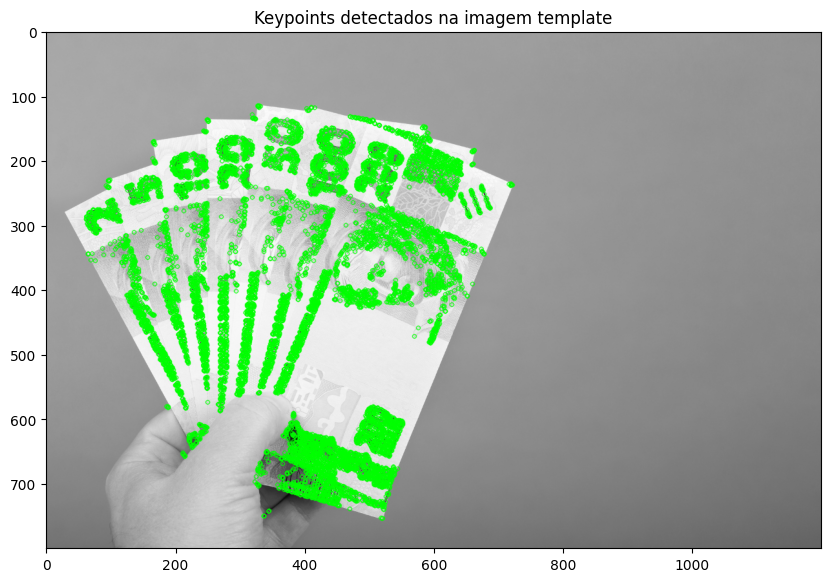

In [48]:
orb_frame = cv2.ORB_create(nfeatures=20000,
                     fastThreshold=30)
frame = cv2.imread('montante.jpg')
frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
kp_frame, des_frame = orb_frame.detectAndCompute(frame_gray, None)

frame_gray = cv2.drawKeypoints(frame_gray, kp_frame, outImage=None, color=(0,255,0),
                                 flags=cv2.DrawMatchesFlags_DEFAULT)

plt.figure(figsize=(10, 10))
plt.title("Keypoints detectados na imagem template")
plt.imshow(cv2.cvtColor(frame_gray, cv2.COLOR_BGR2RGB))
plt.show()

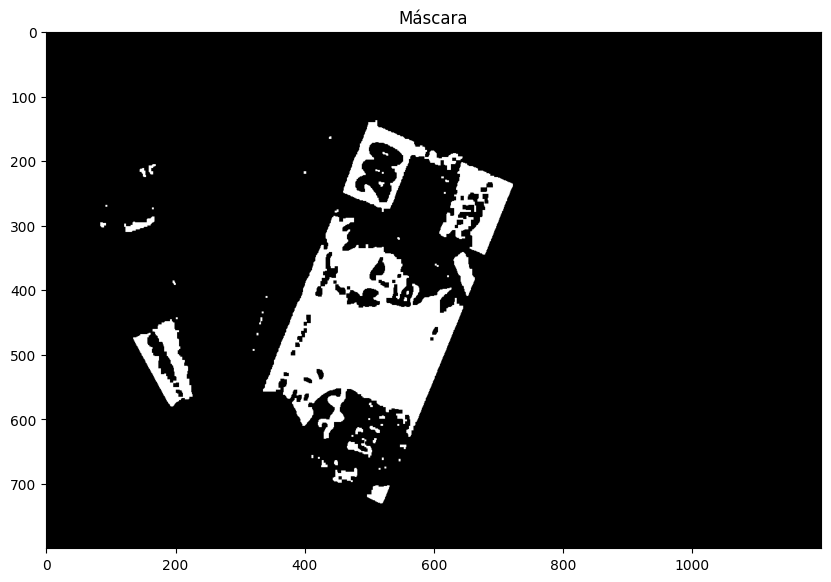

In [50]:
frame = cv2.imread('Exemplo1.png')
img_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)


# Contorno 2
# lower = np.array([88, 33, 116])
# upper = np.array([112, 138, 228])

# Contorno 5
# lower = np.array([143, 15, 128])
# upper = np.array([179, 137, 255])

# Contorno 10
# lower = np.array([0, 64, 148])
# upper = np.array([12, 109, 188])

# Contorno 20
# lower = np.array([0, 76, 191])
# upper = np.array([21, 255, 255])

# Contorno 50
# lower = np.array([0, 25, 179])
# upper = np.array([28, 79, 255])

# Contorno 100
lower = np.array([13, 0, 0])
upper = np.array([90, 40, 165])

# Contorno 200
# lower = np.array([0, 0, 185])
# upper = np.array([179, 8, 255])

mask = cv2.inRange(img_hsv, lower, upper)
kernel = np.ones((3,3), np.uint8)
kernel2 = np.ones((5,5), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel2)

plt.figure(figsize=(10, 10))
plt.title("Máscara")
plt.imshow(cv2.cvtColor(mask, cv2.COLOR_GRAY2RGB))
plt.show()

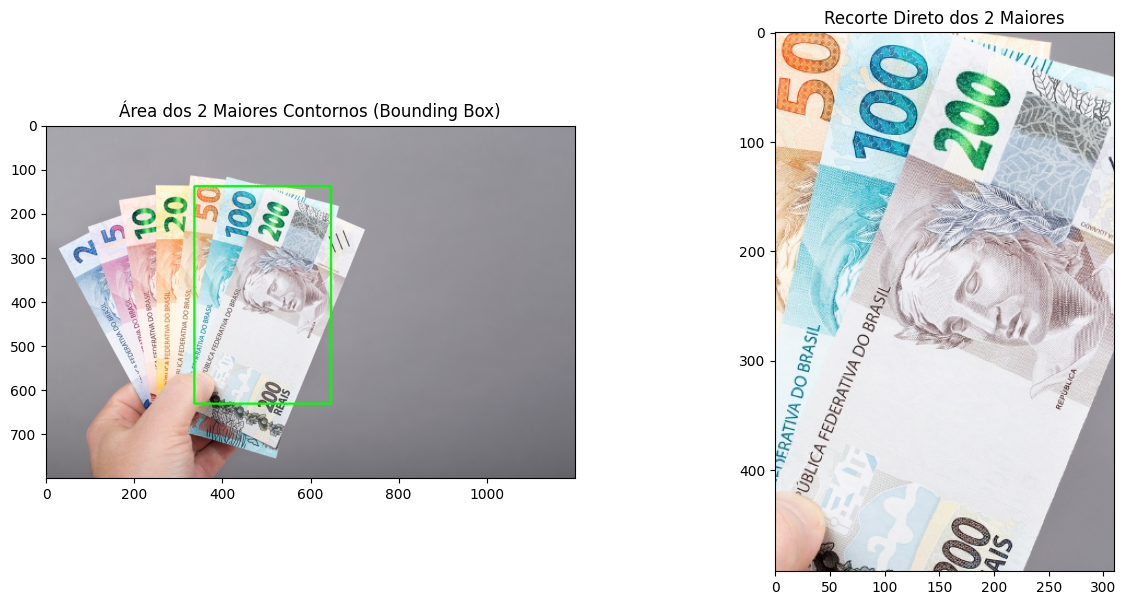

In [51]:
contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

if len(contornos) > 0:
    # Ordena os contornos de forma decrescente com base na área
    contornos_ordenados = sorted(contornos, key=cv2.contourArea, reverse=True)

    # Seleciona até os 2 maiores contornos
    maiores_contornos = contornos_ordenados[:2]

    # Agrupa os pontos desses 2 maiores contornos
    pontos_selecionados = np.vstack(maiores_contornos)

    # Obtém o retângulo envolvente (bounding box) que engloba apenas esses 2 maiores contornos
    x, y, w, h = cv2.boundingRect(pontos_selecionados)

    # Realiza o recorte direto da imagem baseando-se nessa área
    recorte_direto = frame[y:y+h, x:x+w]

    # Exibe a imagem original destacando a região e o respectivo recorte plano
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    frame_retangulo = frame.copy()
    cv2.rectangle(frame_retangulo, (x, y), (x + w, y + h), (0, 255, 0), 4)

    axes[0].set_title("Área dos 2 Maiores Contornos (Bounding Box)")
    axes[0].imshow(cv2.cvtColor(frame_retangulo, cv2.COLOR_BGR2RGB))

    axes[1].set_title("Recorte Direto dos 2 Maiores")
    axes[1].imshow(cv2.cvtColor(recorte_direto, cv2.COLOR_BGR2RGB))

    plt.show()
else:
    print("ERRO: Nenhum contorno encontrado para realizar o recorte.")

Matches filtrados por ratio: 20
Inliers Geométricos (RANSAC): 19

[SUCESSO] Confirmação obtida!


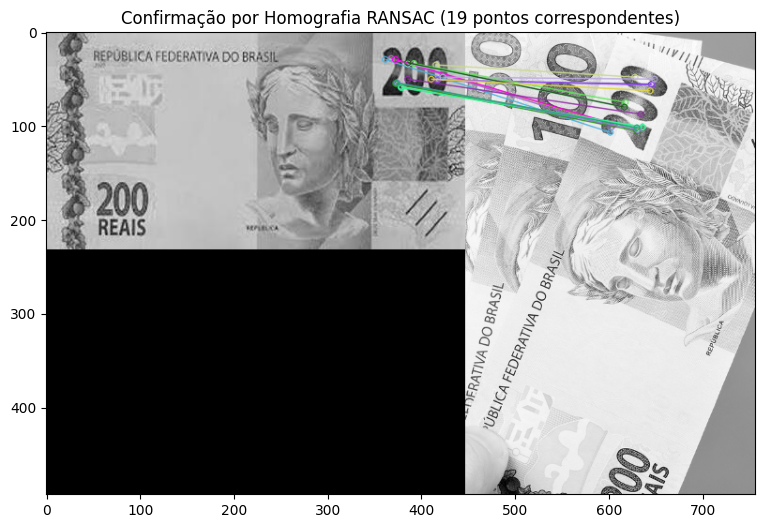

In [53]:
# 1. Converter a nota alinhada para escala de cinza
nota_alinhada_gray = cv2.cvtColor(recorte_direto, cv2.COLOR_BGR2GRAY)

# 2. Configurar um detector ORB robusto e específico para lidar com diferenças de escala
orb_local = cv2.ORB_create(
    nfeatures=500,
    edgeThreshold=5,
    fastThreshold=20
)

kp_nota, des_nota = orb_local.detectAndCompute(nota_alinhada_gray, None)

# 3. Carregar o template de 2 Reais e recortar a região do número
filename = 'cédula-200-reais_anverso.jpg'
img_template = cv2.imread(filename, 0)
if img_template is not None:
    des_temp = templates_data[filename]['des']
    kp_temp = templates_data[filename]['kp']
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
    if des_nota is not None and des_temp is not None:
        matches = bf.knnMatch(des_temp, des_nota, k=2)

        good_matches = []
        for match_pair in matches:
            if len(match_pair) == 2:
                m, n = match_pair
                if m.distance < 0.75 * n.distance:
                    good_matches.append(m)

        # Filtro geométrico robusto com RANSAC corrigido
        if len(good_matches) >= 4:
            src_pts = np.float32([kp_temp[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
            dst_pts = np.float32([kp_nota[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
            H, mask_ransac = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
            inliers = np.sum(mask_ransac) if mask_ransac is not None else 0
        else:
            inliers = 0
            mask_ransac = None

        print(f"Matches filtrados por ratio: {len(good_matches)}")
        print(f"Inliers Geométricos (RANSAC): {inliers}")

        if len(good_matches) >= 3:
            print("\n[SUCESSO] Confirmação obtida!")
            matches_mascara = mask_ransac.ravel().tolist() if mask_ransac is not None else None
            img_confirmacao = cv2.drawMatches(img_template, kp_temp, nota_alinhada_gray, kp_nota,
                                               good_matches, None, matchesMask=matches_mascara, flags=2)
            plt.figure(figsize=(12, 6))
            plt.title(f"Confirmação por Homografia RANSAC ({inliers} pontos correspondentes)")
            plt.imshow(img_confirmacao, cmap='gray')
            plt.show()
        else:
            # Fallback amigável mostrando os matches diretos para análise visual
            print("\nExibindo correspondências brutas (Ratio Match) para validação visual:")
            img_confirmacao = cv2.drawMatches(img_template, kp_temp, nota_alinhada_gray, kp_nota,
                                               good_matches[:10], None, flags=2)
            plt.figure(figsize=(12, 6))
            plt.title("Análise de Matches do Dígito")
            plt.imshow(img_confirmacao, cmap='gray')
            plt.show()
else:
    print("Não foi possível carregar o template selecionado.")

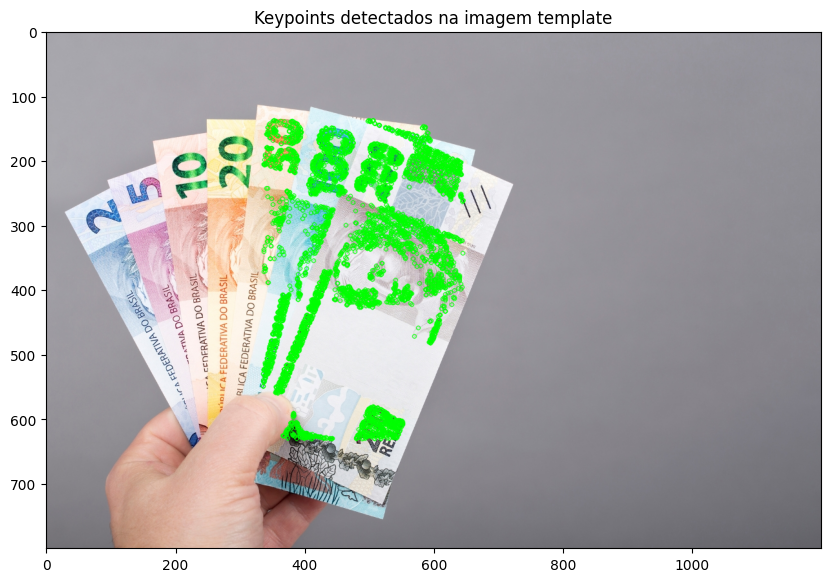

In [54]:
contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

if len(contornos) > 0:
    # Ordena os contornos de forma decrescente com base na área
    contornos_ordenados = sorted(contornos, key=cv2.contourArea, reverse=True)

    # Seleciona até os 2 maiores contornos
    maiores_contornos = contornos_ordenados[:2]

    # Agrupa os pontos desses 2 maiores contornos
    pontos_selecionados = np.vstack(maiores_contornos)

    # Obtém o retângulo envolvente (bounding box) que engloba apenas esses 2 maiores contornos
    x, y, w, h = cv2.boundingRect(pontos_selecionados)

kp_filtrados_val = []
des_filtrados_lista_val = []
for i, kp_f in enumerate(kp_frame):
  xf, yf = int(kp_f.pt[0]), int(kp_f.pt[1])
  if y <= yf < y+h and x <= xf < x+w:
    kp_filtrados_val.append(kp_f)
    des_filtrados_lista_val.append(des_frame[i])

frame_resultado = cv2.drawKeypoints(frame, kp_filtrados_val, outImage=None, color=(0,255,0),
                                 flags=cv2.DrawMatchesFlags_DEFAULT)

plt.figure(figsize=(10, 10))
plt.title("Keypoints detectados na imagem template")
plt.imshow(cv2.cvtColor(frame_resultado, cv2.COLOR_BGR2RGB))
plt.show()